In [103]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.linear_model import LinearRegression

DATA_PATH     = "/content/viral_songs.csv"
TARGET        = "viral"
SCALER        = "standard"
DROP_STREAMS  = False
TEST_SIZE     = 0.2
RANDOM_STATE  = 42

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## İlkin məlumatları nəzərdən keçiririk

In [8]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape, "| sətir:", df.shape[0], "| sütun:", df.shape[1])
print("ndim:", df.ndim, "| size:", df.size)
print("\nColumns:", df.columns.tolist())

Shape: (10000, 17) | sətir: 10000 | sütun: 17
ndim: 2 | size: 170000

Columns: ['track_id', 'track_name', 'artist', 'genre', 'release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db', 'streams', 'viral']


In [9]:
df.dtypes

,0
track_id,object
track_name,object
artist,object
genre,object
release_year,int64
duration_sec,int64
danceability,float64
energy,float64
valence,float64
tempo_bpm,float64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  

In [11]:
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [12]:
df.tail()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
9995,track_09996,Track_09996,Artist_1357,Latin,2011,184,0.786,0.774,0.778,91.4,0.000,0.216,0.273,0.287,-6.35,1865425,1
9996,track_09997,Track_09997,Artist_0123,Classical,2012,165,0.463,0.381,0.631,79.0,0.943,0.000,0.215,0.178,-8.22,186073,0
9997,track_09998,Track_09998,Artist_0504,Rock,2014,242,0.567,0.842,0.611,132.1,0.384,0.124,0.203,0.344,-11.01,55762,0
9998,track_09999,Track_09999,Artist_0801,Hip-Hop,2012,165,0.815,0.901,0.569,91.2,0.124,0.000,0.125,0.061,-7.52,3710114,1
9999,track_10000,Track_10000,Artist_1393,Jazz,2025,312,0.500,0.446,0.510,101.5,0.560,0.137,0.178,0.221,-8.97,149232,0


In [13]:
df.sample(5, random_state=42)

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
6252,track_06253,Track_06253,Artist_0975,Pop,2017,199,0.761,0.415,0.558,122.7,0.048,0.000,0.000,0.392,-11.90,23207,0
4684,track_04685,Track_04685,Artist_0572,Rock,2019,238,0.351,0.844,0.635,106.6,0.175,0.419,0.088,0.290,-7.58,248945,1
1731,track_01732,Track_01732,Artist_0078,Classical,2012,195,0.334,0.302,0.592,89.9,0.821,0.018,0.128,0.445,-8.85,81521,0
4742,track_04743,Track_04743,Artist_1001,Country,2012,65,0.818,0.716,0.415,108.6,0.158,0.092,0.135,0.094,-2.35,208598,0
4521,track_04522,Track_04522,Artist_0817,Latin,2024,228,0.821,0.762,0.850,121.3,0.207,0.000,0.000,0.136,-9.30,14177814,1


In [14]:
df.describe().round(3)

,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,1.000000e+04,10000.00
mean,2017.499,208.777,0.612,0.652,0.582,110.976,0.296,0.177,0.087,0.185,-7.976,2.415685e+06,0.36
std,4.608,49.967,0.193,0.188,0.178,19.017,0.264,0.161,0.070,0.114,2.976,9.721026e+06,0.48
min,2010.000,60.000,0.000,0.005,0.000,50.000,0.000,0.000,0.000,0.000,-18.740,1.340000e+02,0.00
25%,2013.000,175.000,0.482,0.529,0.459,98.000,0.085,0.017,0.027,0.099,-9.980,8.671450e+04,0.00
50%,2018.000,209.000,0.624,0.669,0.582,111.300,0.235,0.154,0.080,0.180,-7.980,3.290580e+05,0.00
75%,2022.000,242.000,0.753,0.787,0.703,124.500,0.441,0.288,0.134,0.264,-5.990,1.343092e+06,1.00
max,2025.000,433.000,1.000,1.000,1.000,177.800,1.000,0.934,0.381,0.623,0.000,4.430683e+08,1.00


In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
track_id,10000,10000,track_09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,10000,10000,Track_09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,10000,1987,Artist_0796,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,10000,10,Rock,1084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,10000.0,NaN,NaN,NaN,2017.4994,4.607854,2010.0,2013.0,2018.0,2022.0,2025.0
duration_sec,10000.0,NaN,NaN,NaN,208.7768,49.967024,60.0,175.0,209.0,242.0,433.0
danceability,10000.0,NaN,NaN,NaN,0.611709,0.192612,0.0,0.482,0.624,0.753,1.0
energy,10000.0,NaN,NaN,NaN,0.651938,0.187686,0.005,0.529,0.669,0.787,1.0
valence,10000.0,NaN,NaN,NaN,0.58228,0.177984,0.0,0.459,0.582,0.703,1.0
tempo_bpm,10000.0,NaN,NaN,NaN,110.97594,19.017206,50.0,98.0,111.3,124.5,177.8


In [58]:
print(df.loc[0:2, ["track_id", "genre", "streams"]])
print()
print(df.iloc[0:2, [0, 3, 15]])

      track_id       genre  streams
0  track_00001         Pop   661412
1  track_00002  Electronic  1114175
2  track_00003     Hip-Hop   105832

      track_id       genre  streams
0  track_00001         Pop   661412
1  track_00002  Electronic  1114175


##  Problemleri/boşlquları aşkar edirik

In [104]:
print("Real NaN (cəmi):", int(df.isna().sum().sum()))
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(2)})
display(miss.sort_values("missing", ascending=False).head(5))

placeholders = ["unknown", "n/a", "na", "none", "null", "-", "?", ""]
text_cols = df.select_dtypes(exclude="number").columns.tolist()
ph = {c: int(df[c].str.strip().str.lower().isin(placeholders).sum()) for c in text_cols}
print("Gizli boşluq (unknown, n/a, ...) mətn sütunlarında:", ph)

Real NaN (cəmi): 0


,missing,missing_pct
track_id,0,0.0
track_name,0,0.0
artist,0,0.0
genre,0,0.0
release_year,0,0.0


Gizli boşluq (unknown, n/a, ...) mətn sütunlarında: {'track_id': 0, 'track_name': 0, 'artist': 0, 'genre': 0}


In [59]:
print("Tam dublikat sətir:", int(df.duplicated().sum()))
print("track_id dublikatı:", int(df["track_id"].duplicated().sum()), "| unikal:", df["track_id"].is_unique)
print("track_name dublikatı:", int(df["track_name"].duplicated().sum()))
print("Unikal artist sayı:", df["artist"].nunique(), "| bir artistin ən çox mahnısı:", int(df["artist"].value_counts().max()))

Tam dublikat sətir: 0
track_id dublikatı: 0 | unikal: True
track_name dublikatı: 0
Unikal artist sayı: 1987 | bir artistin ən çox mahnısı: 15


In [60]:
ws = {c: int((df[c] != df[c].str.strip()).sum()) for c in text_cols}
print("Əvvəl/sonra boşluq olan sətirlər:", ws)
print("genre (unikal):", sorted(df["genre"].unique()))
print("genre unikal sayı (olduğu kimi):", df["genre"].nunique(),
      "| strip+lower-dən sonra:", df["genre"].str.strip().str.lower().nunique())

Əvvəl/sonra boşluq olan sətirlər: {'track_id': 0, 'track_name': 0, 'artist': 0, 'genre': 0}
genre (unikal): ['Classical', 'Country', 'Electronic', 'Hip-Hop', 'Indie', 'Jazz', 'Latin', 'Pop', 'R&B', 'Rock']
genre unikal sayı (olduğu kimi): 10 | strip+lower-dən sonra: 10


In [61]:
unit_cols = ["danceability", "energy", "valence", "acousticness", "instrumentalness", "speechiness", "liveness"]
rng = df[unit_cols].agg(["min", "max"]).T
rng["outside_0_1"] = ((df[unit_cols] < 0) | (df[unit_cols] > 1)).sum()
display(rng)
print("release_year aralığı:", df["release_year"].min(), "-", df["release_year"].max())
print("duration_sec aralığı:", df["duration_sec"].min(), "-", df["duration_sec"].max())
print("streams <= 0 olan sətir:", int((df["streams"] <= 0).sum()))
print("loudness_db > 0 olan sətir:", int((df["loudness_db"] > 0).sum()))

,min,max,outside_0_1
danceability,0.000,1.000,0
energy,0.005,1.000,0
valence,0.000,1.000,0
acousticness,0.000,1.000,0
instrumentalness,0.000,0.934,0
speechiness,0.000,0.381,0
liveness,0.000,0.623,0


release_year aralığı: 2010 - 2025
duration_sec aralığı: 60 - 433
streams <= 0 olan sətir: 0
loudness_db > 0 olan sətir: 0


In [62]:
num_all = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
special = pd.DataFrame({
    "zeros":        [(df[c] == 0).sum() for c in num_all],
    "at_min":       [(df[c] == df[c].min()).sum() for c in num_all],
    "at_max":       [(df[c] == df[c].max()).sum() for c in num_all],
}, index=num_all)
display(special)

,zeros,at_min,at_max
release_year,0,600,609
duration_sec,0,14,1
danceability,11,11,109
energy,0,1,211
valence,4,4,112
tempo_bpm,0,4,1
acousticness,1392,1392,160
instrumentalness,2258,2258,1
speechiness,1574,1574,1
liveness,656,656,1


In [63]:
display(df.groupby(TARGET)["streams"].agg(["count", "min", "median", "mean", "max"]).round(0))

,count,min,median,mean,max
viral,,,,,
0,6395,134,149193.0,471461.0,19345373
1,3605,8937,1694602.0,5864593.0,443068342


##  Təmizləmə

In [105]:
clean = df.copy()

#sütun adlarını standartlaşdırırıq
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")

#mətn sütunlarını standartlaşdırırıq
for c in clean.select_dtypes(exclude="number").columns:
    clean[c] = clean[c].str.strip()

#dublikatlar
n_before = len(clean)
clean = clean.drop_duplicates()
print("Silinən dublikat:", n_before - len(clean))

#boşluq yoxdur ona görə fillna/dropna tətbiq etmirik
assert clean.isna().sum().sum() == 0


clean = clean.drop(columns=["track_id", "track_name"])


clean["viral_label"] = clean[TARGET].replace({0: "Not Viral", 1: "Viral"})

clean = clean.reset_index(drop=True)
print("Clean shape:", clean.shape)
print(clean.dtypes)

Silinən dublikat: 0
Clean shape: (10000, 16)
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
viral_label          object
dtype: object


##  Feature engineering

In [66]:
clean["era"] = np.where(clean["release_year"] >= 2020, "2020s", "2010s")


print("qcut sərhədləri:", list(pd.qcut(clean["streams"], q=4).cat.categories))
clean["streams_group"] = pd.qcut(clean["streams"], q=4, labels=["Low", "Medium", "High", "Very High"])

display(clean["era"].value_counts())
display(clean["streams_group"].value_counts().sort_index())
display(pd.crosstab(clean["streams_group"], clean[TARGET]))
display(clean.head())

qcut sərhədləri: [Interval(133.999, 86714.5, closed='right'), Interval(86714.5, 329058.0, closed='right'), Interval(329058.0, 1343091.75, closed='right'), Interval(1343091.75, 443068342.0, closed='right')]


,count
era,
2010s,6230
2020s,3770


,count
streams_group,
Low,2500
Medium,2500
High,2500
Very High,2500


viral,0,1
streams_group,,
Low,2378,122
Medium,2024,476
High,1480,1020
Very High,513,1987


,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral,viral_label,era,streams_group
0,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1,Viral,2010s,High
1,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1,Viral,2010s,High
2,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1,Viral,2010s,Medium
3,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0,Not Viral,2010s,High
4,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1,Viral,2010s,Very High


## Sorğu, filtr və sıralama

In [67]:
print("streams > 10 000 000 olan mahnılar:", int((clean["streams"] > 10_000_000).sum()))
display(clean.loc[clean["streams"] > 50_000_000, ["artist", "genre", "streams", TARGET]].sort_values("streams", ascending=False).head())

mask = (clean["genre"] == "Pop") & (clean["danceability"] >= 0.8)
print("Pop və danceability >= 0.8:", int(mask.sum()))
print("genre in [Pop, Latin]:", int(clean["genre"].isin(["Pop", "Latin"]).sum()))
print("tempo 100-120 arası:", int(clean["tempo_bpm"].between(100, 120).sum()))
print("viral olub:", int((clean[TARGET] == 1).sum()))

streams > 10 000 000 olan mahnılar: 528


,artist,genre,streams,viral
6786,Artist_1596,Pop,443068342,1
637,Artist_1413,Rock,317562436,1
3338,Artist_0452,Hip-Hop,184347884,1
5736,Artist_0022,Hip-Hop,163017304,1
1167,Artist_1692,R&B,162740944,1


Pop və danceability >= 0.8: 194
genre in [Pop, Latin]: 2032
tempo 100-120 arası: 3889
viral olub: 3605


In [68]:
display(clean.sort_values(by="streams", ascending=False).head())
display(clean.sort_values(by=["genre", "danceability"], ascending=[True, False])[["genre", "danceability", "streams"]].head())

,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral,viral_label,era,streams_group
6786,Artist_1596,Pop,2012,240,0.822,0.663,0.663,110.3,0.280,0.256,0.029,0.283,-5.26,443068342,1,Viral,2010s,Very High
637,Artist_1413,Rock,2023,207,0.570,0.902,0.387,148.0,0.009,0.552,0.000,0.148,-8.45,317562436,1,Viral,2020s,Very High
3338,Artist_0452,Hip-Hop,2016,127,0.832,0.682,0.850,66.2,0.193,0.271,0.019,0.064,-9.02,184347884,1,Viral,2010s,Very High
5736,Artist_0022,Hip-Hop,2023,229,0.677,0.527,0.692,124.2,0.142,0.337,0.016,0.177,-8.19,163017304,1,Viral,2020s,Very High
1167,Artist_1692,R&B,2020,183,0.772,0.632,0.415,82.1,0.439,0.000,0.141,0.194,-11.01,162740944,1,Viral,2020s,Very High


,genre,danceability,streams
6963,Classical,0.677,17449
3354,Classical,0.676,414373
9976,Classical,0.651,626211
5570,Classical,0.639,1601105
6019,Classical,0.632,20075


## Univariate təhlil

,count,percent
viral,,
0,6395,63.95
1,3605,36.05


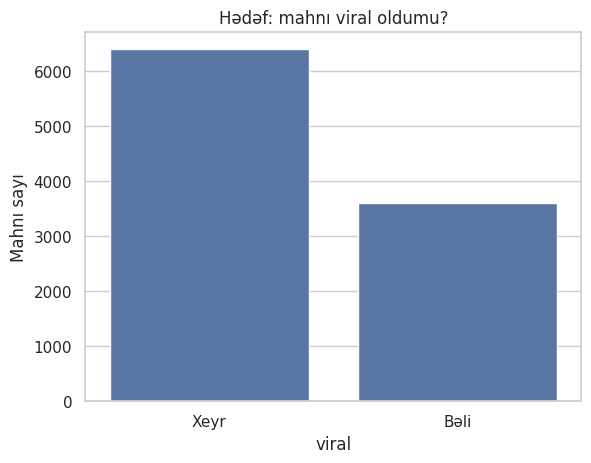

In [69]:
counts = clean[TARGET].value_counts()
display(pd.DataFrame({"count": counts, "percent": (counts / len(clean) * 100).round(2)}))
sns.countplot(data=clean, x=TARGET)
plt.title("Hədəf: mahnı viral oldumu?")
plt.xlabel("viral")
plt.ylabel("Mahnı sayı")
plt.xticks([0, 1], ["Xeyr", "Bəli"])
plt.show()

,count,percent
genre,,
Rock,1084,10.84
Hip-Hop,1052,10.52
Latin,1030,10.30
Pop,1002,10.02
Indie,993,9.93
Electronic,991,9.91
Classical,991,9.91
Jazz,965,9.65
R&B,950,9.50


genre modası: Rock
release_year modası: 2022


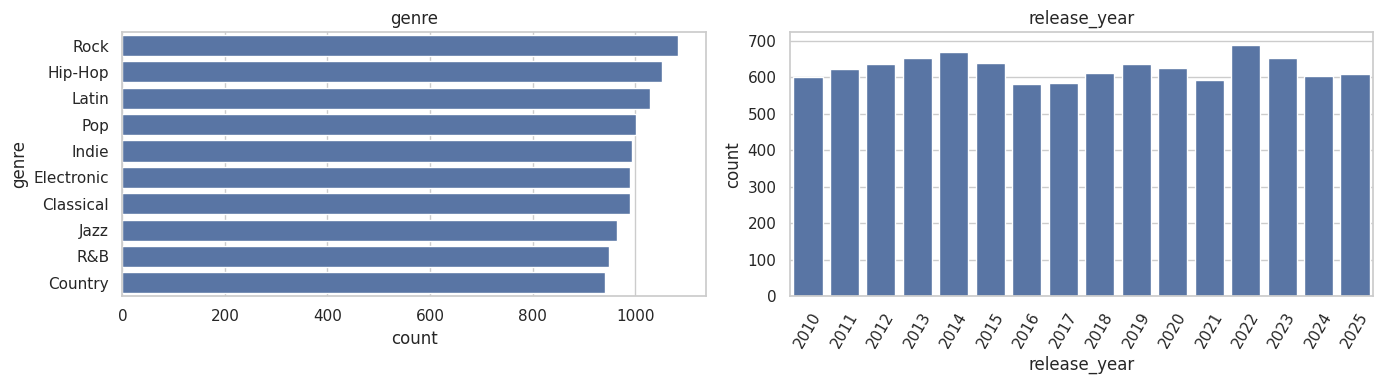

In [70]:
g = clean["genre"].value_counts()
display(pd.DataFrame({"count": g, "percent": (g / len(clean) * 100).round(2)}))
print("genre modası:", clean["genre"].mode()[0])
print("release_year modası:", clean["release_year"].mode()[0])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=clean, y="genre", order=g.index, ax=axes[0]); axes[0].set_title("genre")
sns.countplot(data=clean, x="release_year", ax=axes[1]); axes[1].set_title("release_year")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

In [71]:
num_cols = ["release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm",
            "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db", "streams"]
stats = pd.DataFrame({
    "mean": clean[num_cols].mean(), "median": clean[num_cols].median(), "std": clean[num_cols].std(),
    "min": clean[num_cols].min(), "max": clean[num_cols].max(),
})
stats["range"] = stats["max"] - stats["min"]
stats["Q1"] = clean[num_cols].quantile(0.25)
stats["Q3"] = clean[num_cols].quantile(0.75)
stats["IQR"] = stats["Q3"] - stats["Q1"]
stats["skew"] = clean[num_cols].skew()
display(stats.round(3))

,mean,median,std,min,max,range,Q1,Q3,IQR,skew
release_year,2017.499,2018.000,4.608,2010.000,2.025000e+03,1.500000e+01,2013.000,2022.000,9.000,0.002
duration_sec,208.777,209.000,49.967,60.000,4.330000e+02,3.730000e+02,175.000,242.000,67.000,0.037
danceability,0.612,0.624,0.193,0.000,1.000000e+00,1.000000e+00,0.482,0.753,0.271,-0.295
energy,0.652,0.669,0.188,0.005,1.000000e+00,9.950000e-01,0.529,0.787,0.258,-0.373
valence,0.582,0.582,0.178,0.000,1.000000e+00,1.000000e+00,0.459,0.703,0.244,0.020
tempo_bpm,110.976,111.300,19.017,50.000,1.778000e+02,1.278000e+02,98.000,124.500,26.500,-0.061
acousticness,0.296,0.235,0.264,0.000,1.000000e+00,1.000000e+00,0.085,0.441,0.356,0.924
instrumentalness,0.177,0.154,0.161,0.000,9.340000e-01,9.340000e-01,0.017,0.288,0.271,0.739
speechiness,0.087,0.080,0.070,0.000,3.810000e-01,3.810000e-01,0.027,0.134,0.107,0.579
liveness,0.185,0.180,0.114,0.000,6.230000e-01,6.230000e-01,0.099,0.264,0.165,0.293


In [73]:
print("energy var (pandas, ddof=1):", round(clean["energy"].var(), 6))
print("energy var (np.var, ddof=0) :", round(np.var(clean["energy"]), 6))
print("energy std (pandas)         :", round(clean["energy"].std(), 6))

energy var (pandas, ddof=1): 0.035226
energy var (np.var, ddof=0) : 0.035223
energy std (pandas)         : 0.187686


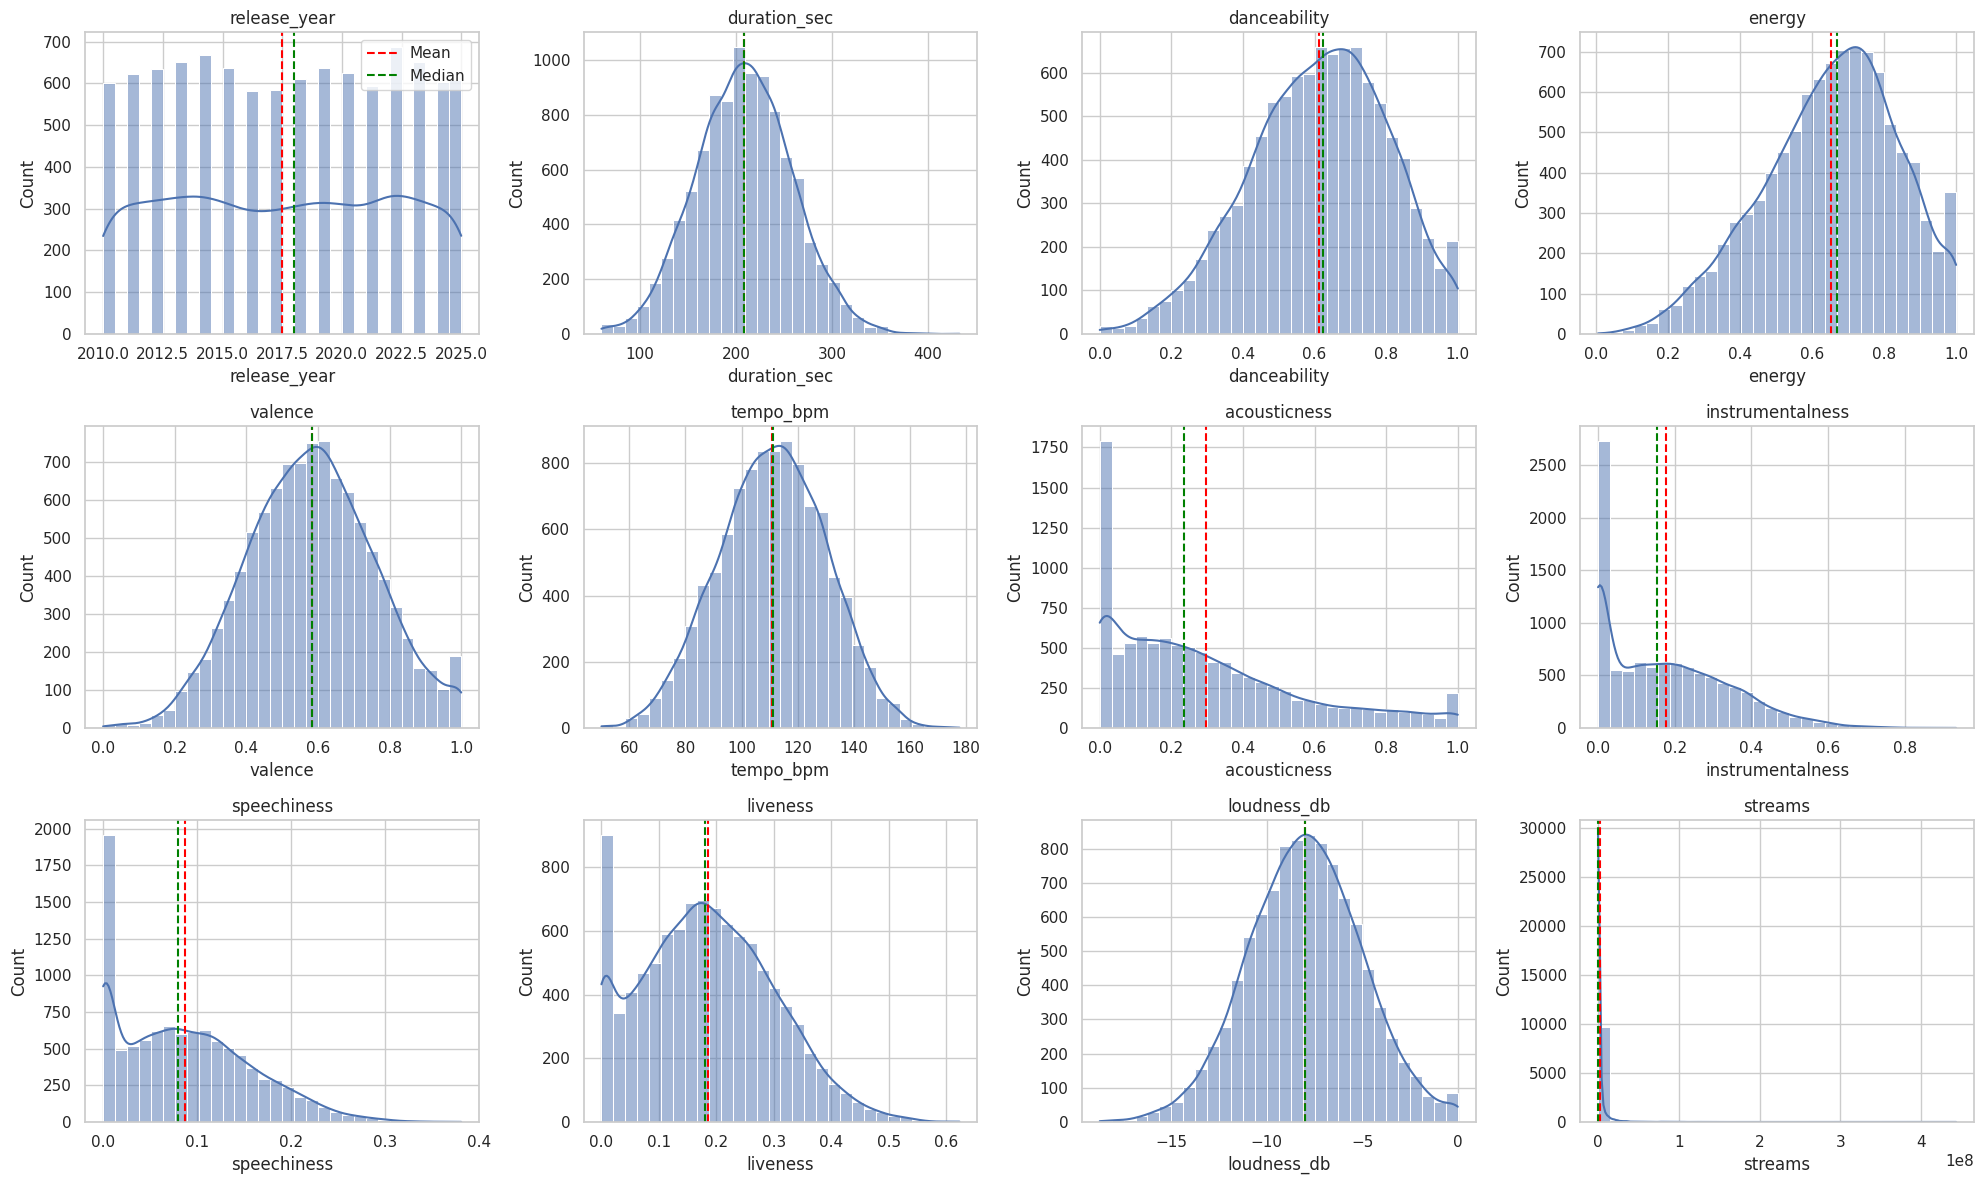

In [74]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=clean, x=col, bins=30, kde=True, ax=ax)
    ax.axvline(clean[col].mean(), color="red", linestyle="--", label="Mean")
    ax.axvline(clean[col].median(), color="green", linestyle="--", label="Median")
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

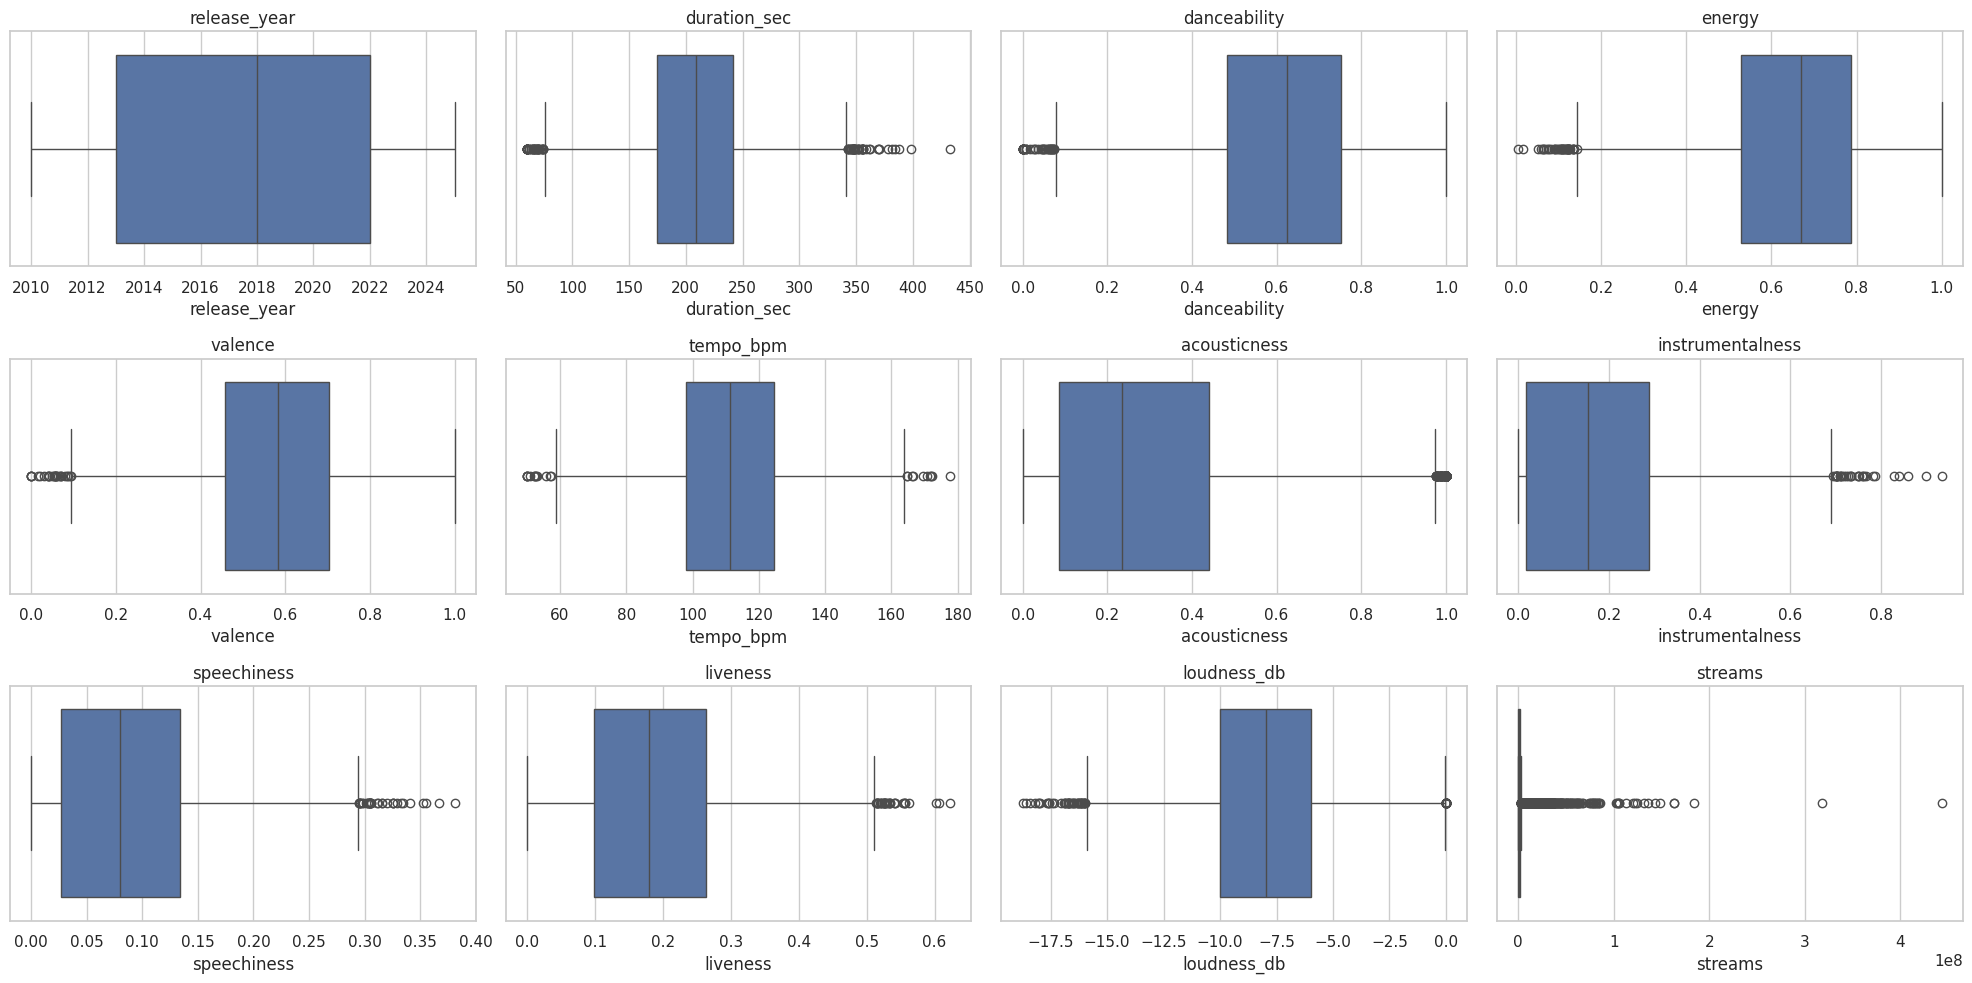

In [75]:
fig, axes = plt.subplots(3, 4, figsize=(20, 10))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=clean, x=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

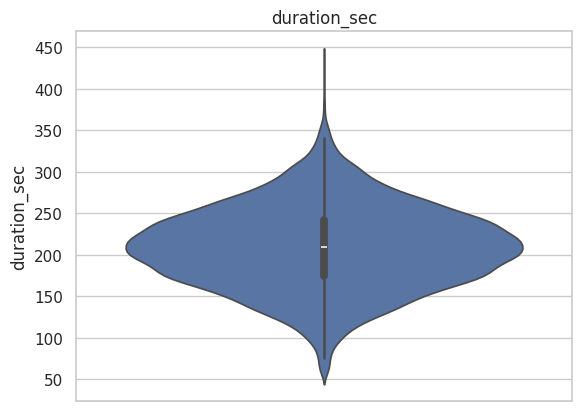

In [76]:
sns.violinplot(data=clean["duration_sec"])
plt.title("duration_sec")
plt.show()

In [77]:
rows = []
for col in num_cols:
    q1, q3 = clean[col].quantile(0.25), clean[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((clean[col] < lower) | (clean[col] > upper)).sum())
    rows.append([col, q1, q3, iqr, lower, upper, n_out, round(n_out / len(clean) * 100, 2)])
out_table = pd.DataFrame(rows, columns=["column", "Q1", "Q3", "IQR", "lower", "upper", "n_outliers", "pct"])
display(out_table.round(3))

,column,Q1,Q3,IQR,lower,upper,n_outliers,pct
0,release_year,2013.000,2022.000,9.000,1999.500,2035.500,0,0.00
1,duration_sec,175.000,242.000,67.000,74.500,342.500,84,0.84
2,danceability,0.482,0.753,0.271,0.075,1.160,39,0.39
3,energy,0.529,0.787,0.258,0.142,1.174,42,0.42
4,valence,0.459,0.703,0.244,0.093,1.069,28,0.28
5,tempo_bpm,98.000,124.500,26.500,58.250,164.250,23,0.23
6,acousticness,0.085,0.441,0.356,-0.449,0.975,197,1.97
7,instrumentalness,0.017,0.288,0.271,-0.389,0.694,32,0.32
8,speechiness,0.027,0.134,0.107,-0.134,0.295,35,0.35
9,liveness,0.099,0.264,0.165,-0.148,0.512,33,0.33


In [78]:
q1 = clean["streams"].quantile(0.25); q3 = clean["streams"].quantile(0.75); iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr; upper_bound = q3 + 1.5 * iqr
print(f"streams: Q1={q1}, Q3={q3}, IQR={iqr}, lower={lower_bound}, upper={upper_bound}")
mask = (clean["streams"] > upper_bound) | (clean["streams"] < lower_bound)
streams_outliers = clean[mask]
print("Outlier sayı:", len(streams_outliers))
print("Outlier-lərdə viral payı:", round(streams_outliers[TARGET].mean() * 100, 2), "%")
print("Bütün datada viral payı :", round(clean[TARGET].mean() * 100, 2), "%")
display(streams_outliers[TARGET].value_counts())
display(streams_outliers["genre"].value_counts())
display(streams_outliers[["artist", "genre", "streams", TARGET]].sort_values("streams", ascending=False).head())

streams: Q1=86714.5, Q3=1343091.75, IQR=1256377.25, lower=-1797851.375, upper=3227657.625
Outlier sayı: 1399
Outlier-lərdə viral payı: 89.85 %
Bütün datada viral payı : 36.05 %


,count
viral,
1,1257
0,142


,count
genre,
Hip-Hop,249
Latin,240
Pop,222
Electronic,195
R&B,132
Rock,121
Country,104
Indie,73
Jazz,36


,artist,genre,streams,viral
6786,Artist_1596,Pop,443068342,1
637,Artist_1413,Rock,317562436,1
3338,Artist_0452,Hip-Hop,184347884,1
5736,Artist_0022,Hip-Hop,163017304,1
1167,Artist_1692,R&B,162740944,1


##  Bivariate

In [79]:
ct = pd.crosstab(clean["genre"], clean[TARGET], margins=True, margins_name="Total")
display(ct)
display((pd.crosstab(clean["genre"], clean[TARGET], normalize="index") * 100).round(2).sort_values(1, ascending=False))
display(pd.crosstab(clean["genre"], clean[TARGET], normalize="columns").round(4))

viral,0,1,Total
genre,,,
Classical,979,12,991
Country,717,225,942
Electronic,489,502,991
Hip-Hop,409,643,1052
Indie,855,138,993
Jazz,904,61,965
Latin,364,666,1030
Pop,383,619,1002
R&B,565,385,950


viral,0,1
genre,,
Latin,35.34,64.66
Pop,38.22,61.78
Hip-Hop,38.88,61.12
Electronic,49.34,50.66
R&B,59.47,40.53
Rock,67.34,32.66
Country,76.11,23.89
Indie,86.10,13.90
Jazz,93.68,6.32


viral,0,1
genre,,
Classical,0.1531,0.0033
Country,0.1121,0.0624
Electronic,0.0765,0.1393
Hip-Hop,0.0640,0.1784
Indie,0.1337,0.0383
Jazz,0.1414,0.0169
Latin,0.0569,0.1847
Pop,0.0599,0.1717
R&B,0.0884,0.1068


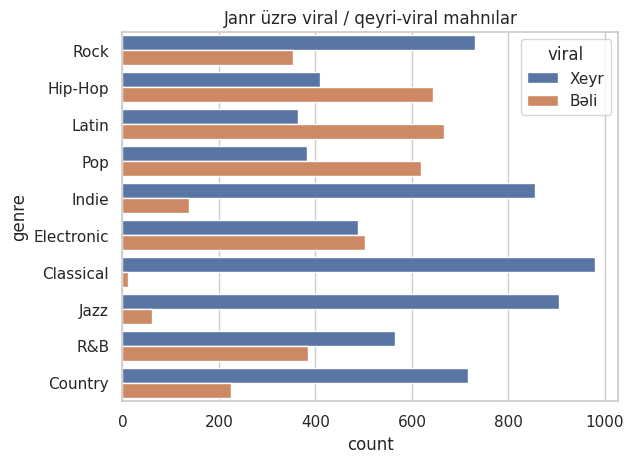

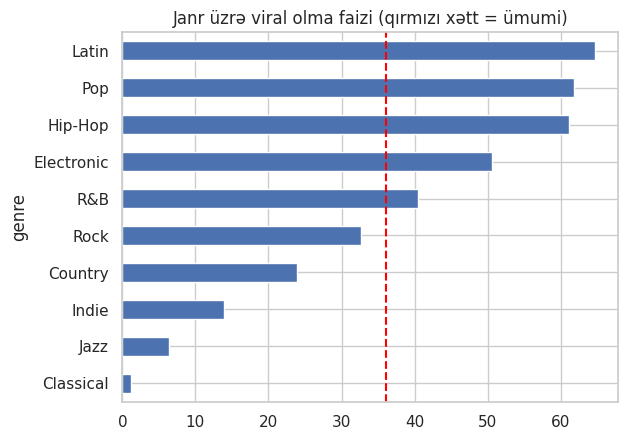

In [80]:
sns.countplot(data=clean, y="genre", hue=TARGET, order=clean["genre"].value_counts().index)
plt.title("Janr üzrə viral / qeyri-viral mahnılar")
plt.legend(title="viral", labels=["Xeyr", "Bəli"])
plt.show()

rate = (pd.crosstab(clean["genre"], clean[TARGET], normalize="index") * 100)[1].sort_values()
rate.plot(kind="barh")
plt.axvline(clean[TARGET].mean() * 100, color="red", linestyle="--")
plt.title("Janr üzrə viral olma faizi (qırmızı xətt = ümumi)")
plt.show()

In [81]:
display(pd.crosstab(clean["era"], clean[TARGET]))
display((pd.crosstab(clean["era"], clean[TARGET], normalize="index") * 100).round(2))
display((clean.groupby("release_year")[TARGET].mean() * 100).round(1))
display((pd.crosstab(clean["streams_group"], clean[TARGET], normalize="index") * 100).round(2))

viral,0,1
era,,
2010s,3999,2231
2020s,2396,1374


viral,0,1
era,,
2010s,64.19,35.81
2020s,63.55,36.45


,viral
release_year,
2010,35.5
2011,35.5
2012,35.0
2013,35.3
2014,37.4
2015,37.5
2016,35.6
2017,33.9
2018,35.7


viral,0,1
streams_group,,
Low,95.12,4.88
Medium,80.96,19.04
High,59.20,40.80
Very High,20.52,79.48


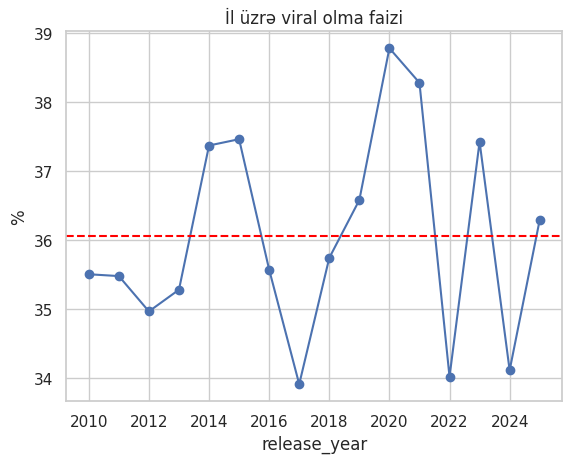

In [82]:
(clean.groupby("release_year")[TARGET].mean() * 100).plot(kind="line", marker="o")
plt.axhline(clean[TARGET].mean() * 100, color="red", linestyle="--")
plt.title("İl üzrə viral olma faizi")
plt.ylabel("%")
plt.show()

In [83]:
display(clean.groupby(TARGET)[num_cols].mean().round(3).T)
display(clean.groupby(TARGET)[num_cols].median().round(3).T)

viral,0,1
release_year,2017.487,2017.521
duration_sec,208.954,208.463
danceability,0.556,0.711
energy,0.609,0.727
valence,0.555,0.631
tempo_bpm,110.742,111.391
acousticness,0.367,0.170
instrumentalness,0.186,0.162
speechiness,0.088,0.086
liveness,0.184,0.186


viral,0,1
release_year,2017.000,2018.000
duration_sec,209.000,208.000
danceability,0.559,0.720
energy,0.620,0.729
valence,0.553,0.631
tempo_bpm,111.100,111.600
acousticness,0.322,0.143
instrumentalness,0.165,0.134
speechiness,0.082,0.078
liveness,0.180,0.180


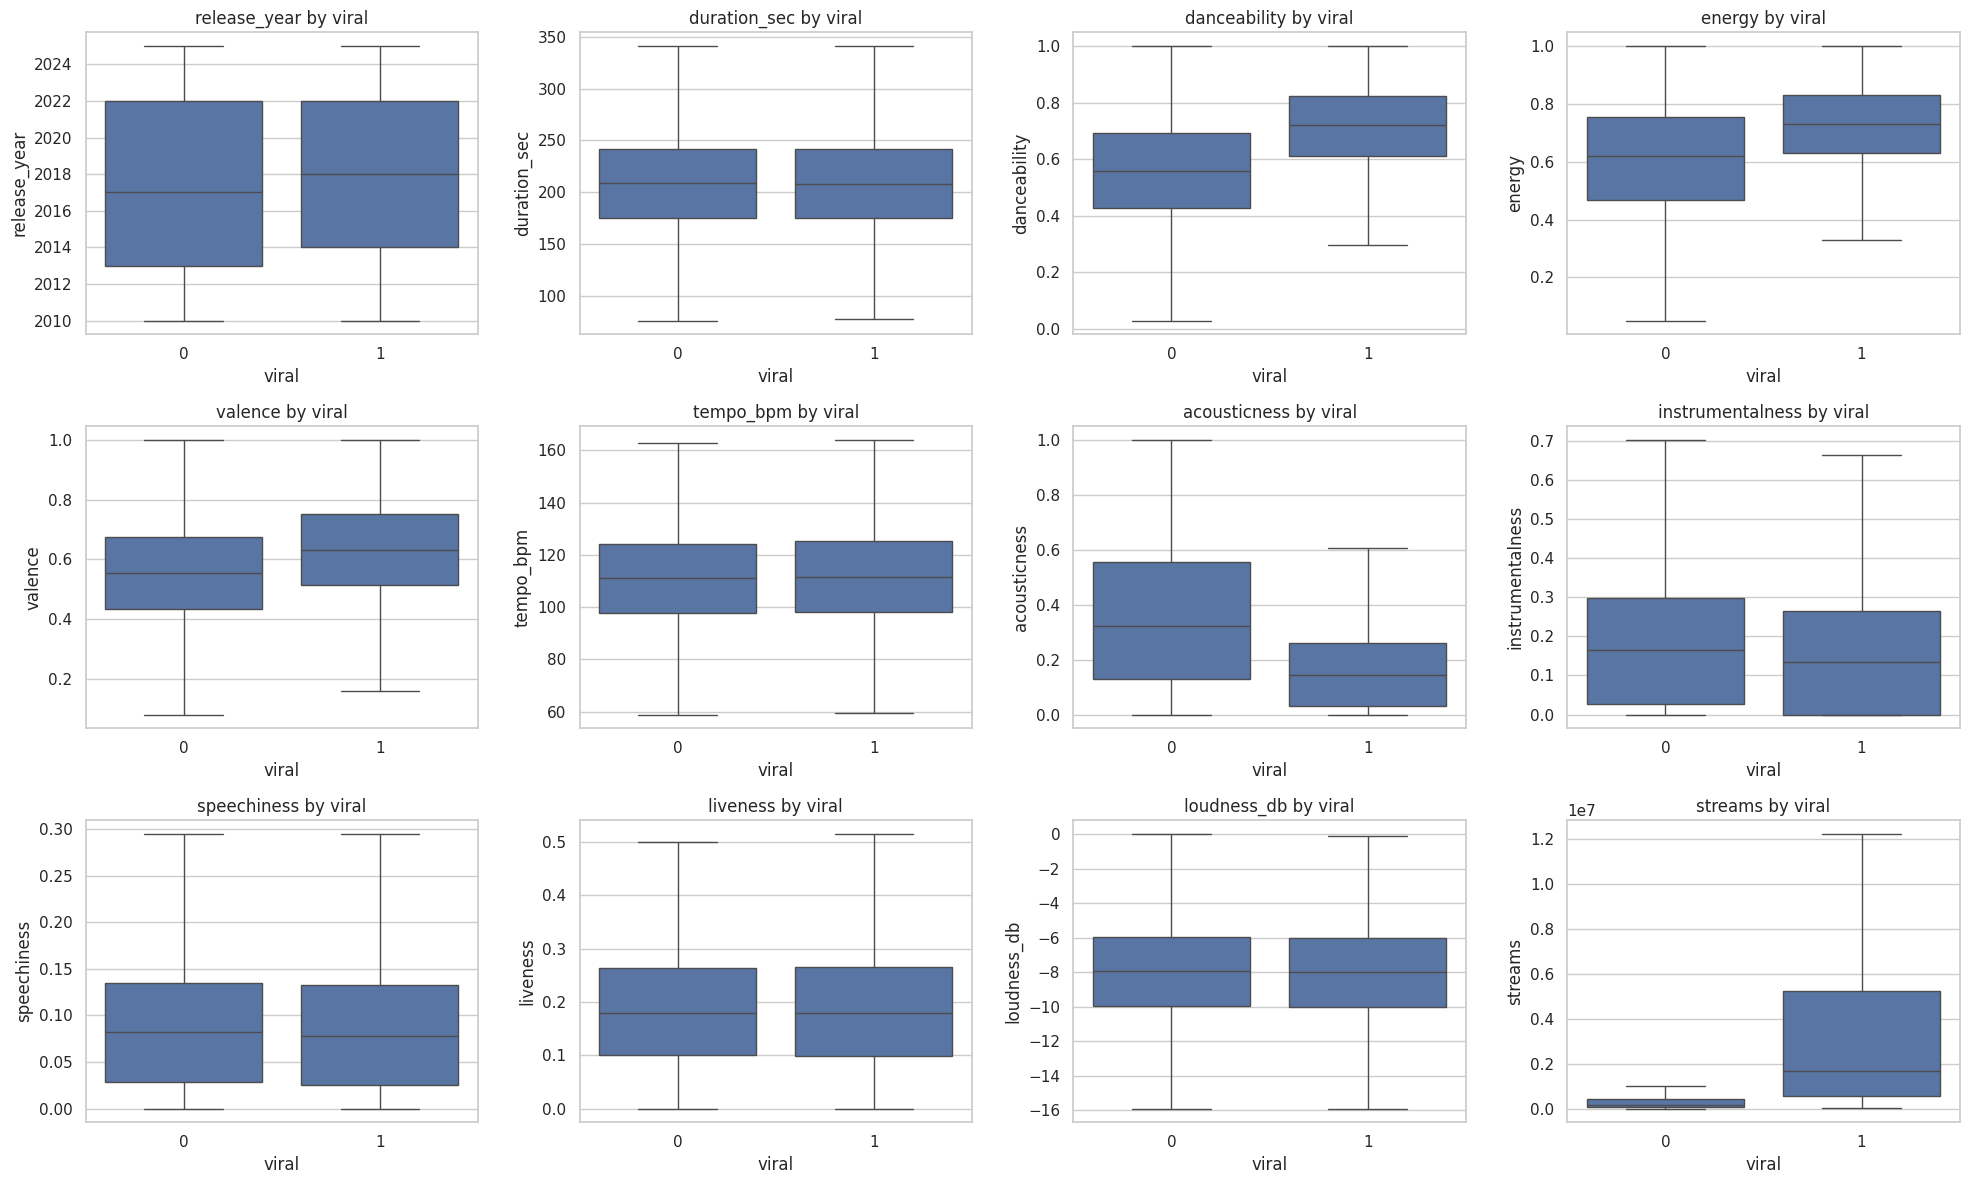

In [84]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=clean, x=TARGET, y=col, showfliers=False, ax=ax)
    ax.set_title(f"{col} by {TARGET}")
plt.tight_layout()
plt.show()

In [85]:
display(clean.groupby("genre")["streams"].agg(["count", "mean", "median", "min", "max"]).round(0).sort_values("median", ascending=False))
display(clean.groupby("genre")[["danceability", "energy", "valence", "acousticness"]].mean().round(3))

,count,mean,median,min,max
genre,,,,,
Latin,1030,4446222.0,895084.0,1240,147966107
Hip-Hop,1052,3966979.0,779180.0,867,184347884
Pop,1002,3394448.0,660266.0,2270,443068342
Electronic,991,3453180.0,539456.0,1638,135865882
R&B,950,2573817.0,339724.0,1718,162740944
Rock,1084,1779353.0,274696.0,1457,317562436
Country,942,1802619.0,226332.0,134,102151833
Indie,993,1351778.0,192274.0,518,113138131
Classical,991,492065.0,159661.0,317,22540375


,danceability,energy,valence,acousticness
genre,,,,
Classical,0.300,0.351,0.459,0.838
Country,0.546,0.651,0.721,0.347
Electronic,0.748,0.814,0.548,0.108
Hip-Hop,0.784,0.683,0.549,0.124
Indie,0.550,0.617,0.475,0.396
Jazz,0.497,0.446,0.557,0.553
Latin,0.801,0.752,0.771,0.172
Pop,0.699,0.721,0.647,0.158
R&B,0.678,0.611,0.603,0.214


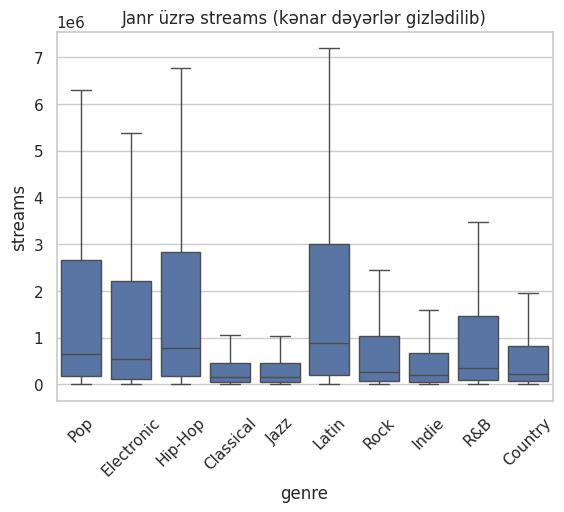

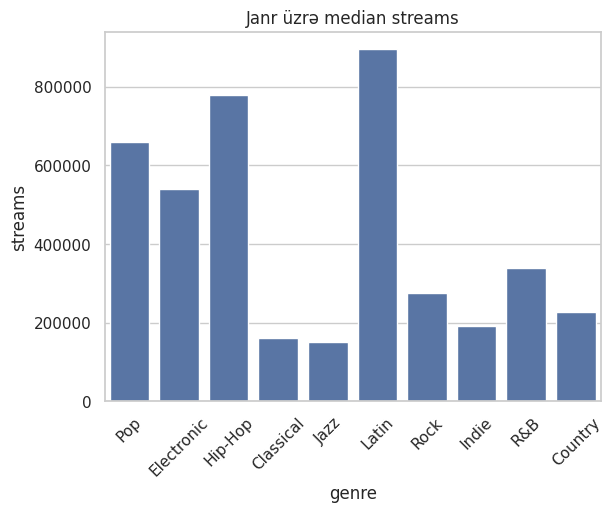

In [86]:
sns.boxplot(data=clean, x="genre", y="streams", showfliers=False)
plt.title("Janr üzrə streams (kənar dəyərlər gizlədilib)")
plt.xticks(rotation=45)
plt.show()

sns.barplot(data=clean, x="genre", y="streams", estimator="median", errorbar=None)
plt.title("Janr üzrə median streams")
plt.xticks(rotation=45)
plt.show()

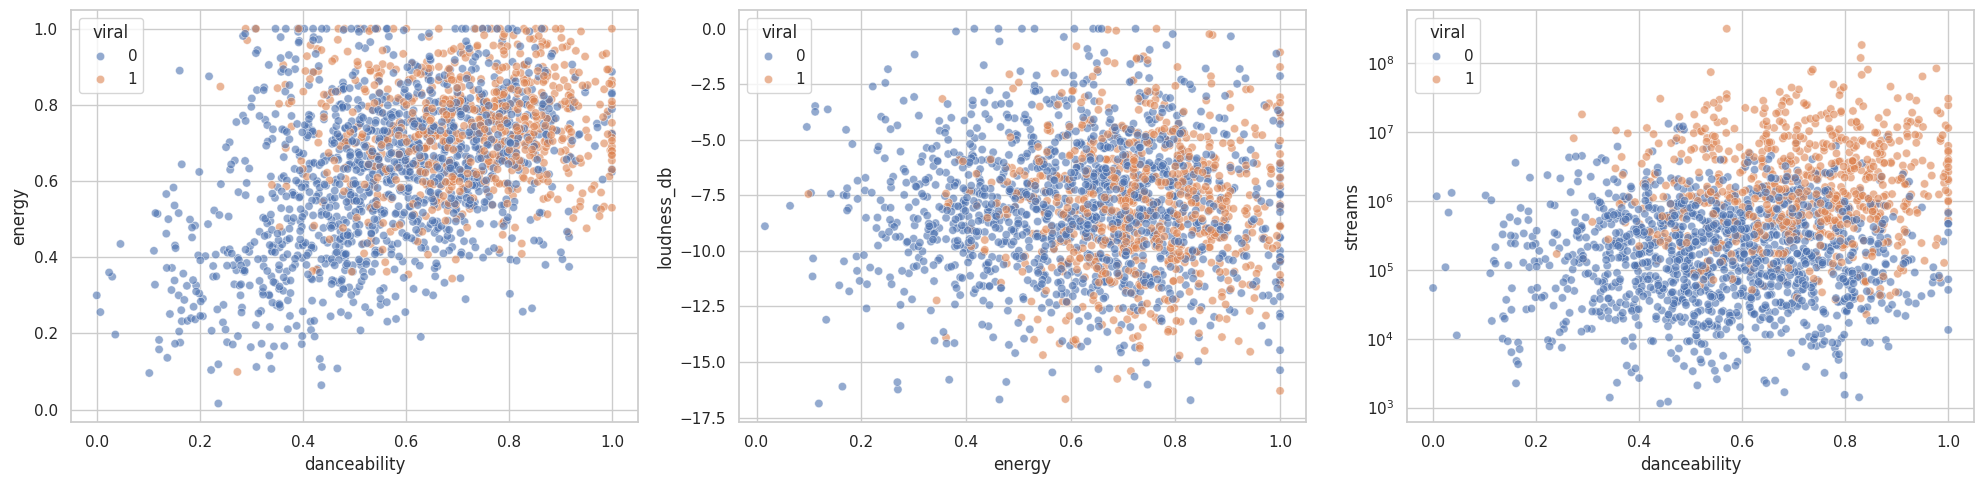

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=clean.sample(2000, random_state=42), x="danceability", y="energy", hue=TARGET, alpha=0.6, ax=axes[0])
sns.scatterplot(data=clean.sample(2000, random_state=42), x="energy", y="loudness_db", hue=TARGET, alpha=0.6, ax=axes[1])
sns.scatterplot(data=clean.sample(2000, random_state=42), x="danceability", y="streams", hue=TARGET, alpha=0.6, ax=axes[2])
axes[2].set_yscale("log")
plt.tight_layout()
plt.show()

## Multivariate





In [88]:
display((clean.groupby(["genre", "era"])[TARGET].mean() * 100).round(1))
summary = clean.groupby(["genre", "era"], as_index=False)[TARGET].mean()
summary["viral_rate"] = summary[TARGET] * 100
display(summary.head())
display(pd.crosstab([clean["genre"], clean["era"]], clean[TARGET]).head(6))

genre       era  
Classical   2010s     1.6
            2020s     0.6
Country     2010s    24.4
            2020s    23.1
Electronic  2010s    51.9
            2020s    48.5
Hip-Hop     2010s    61.5
            2020s    60.4
Indie       2010s    13.7
            2020s    14.3
Jazz        2010s     6.1
            2020s     6.7
Latin       2010s    63.6
            2020s    66.3
Pop         2010s    61.9
            2020s    61.6
R&B         2010s    39.5
            2020s    42.2
Rock        2010s    33.6
            2020s    31.0
Name: viral, dtype: float64

,genre,era,viral,viral_rate
0,Classical,2010s,0.015823,1.582278
1,Classical,2020s,0.005571,0.557103
2,Country,2010s,0.243902,24.390244
3,Country,2020s,0.230978,23.097826
4,Electronic,2010s,0.519231,51.923077


viral               0    1
genre      era            
Classical  2010s  622   10
           2020s  357    2
Country    2010s  434  140
           2020s  283   85
Electronic 2010s  300  324
           2020s  189  178

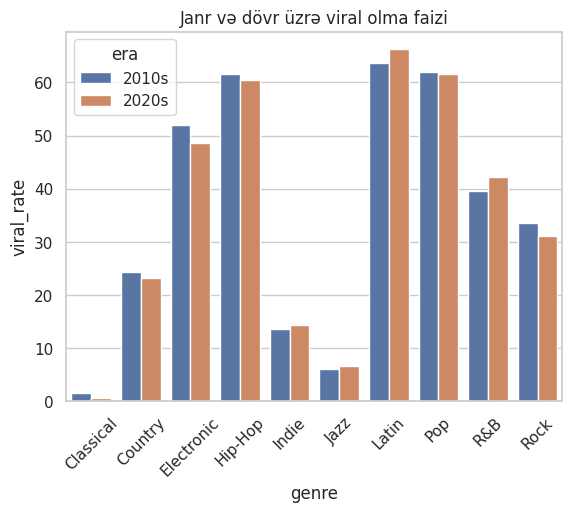

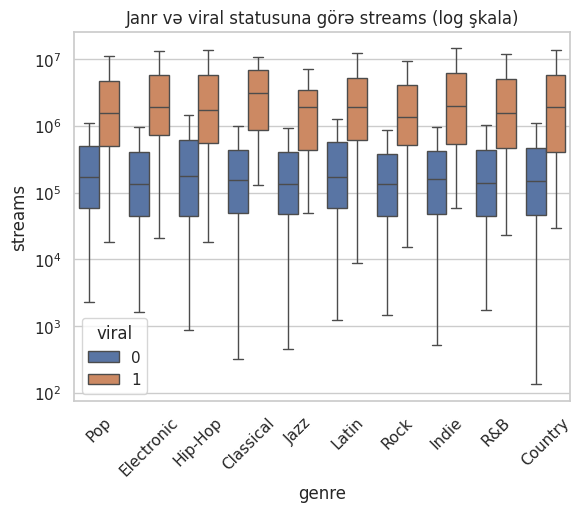

In [89]:
sns.barplot(data=summary, x="genre", y="viral_rate", hue="era")
plt.xticks(rotation=45)
plt.title("Janr və dövr üzrə viral olma faizi")
plt.show()

sns.boxplot(data=clean, x="genre", y="streams", hue=TARGET, showfliers=False)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Janr və viral statusuna görə streams (log şkala)")
plt.show()

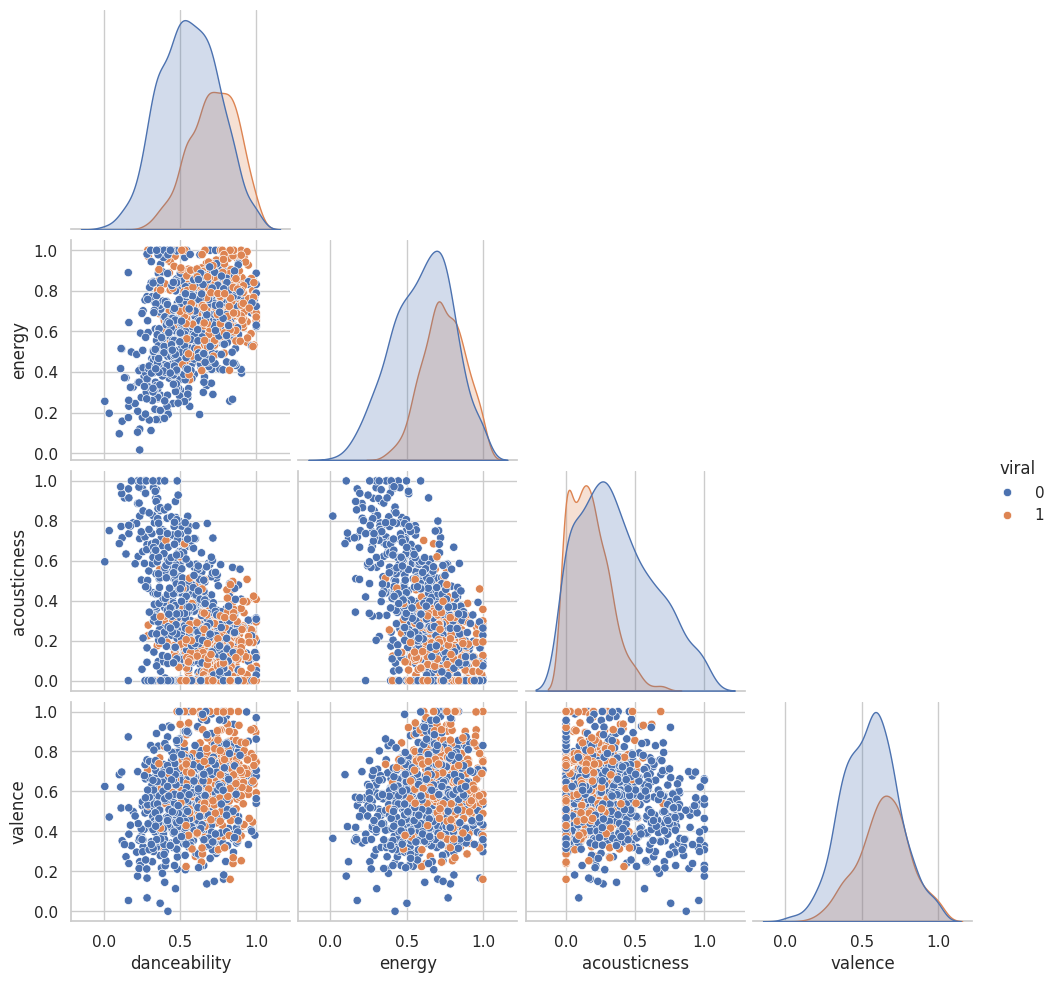

In [90]:
sns.pairplot(clean.sample(1000, random_state=42)[["danceability", "energy", "acousticness", "valence", TARGET]],
             hue=TARGET, corner=True)
plt.show()

## Korrelyasiya (Pearson və Spearman)

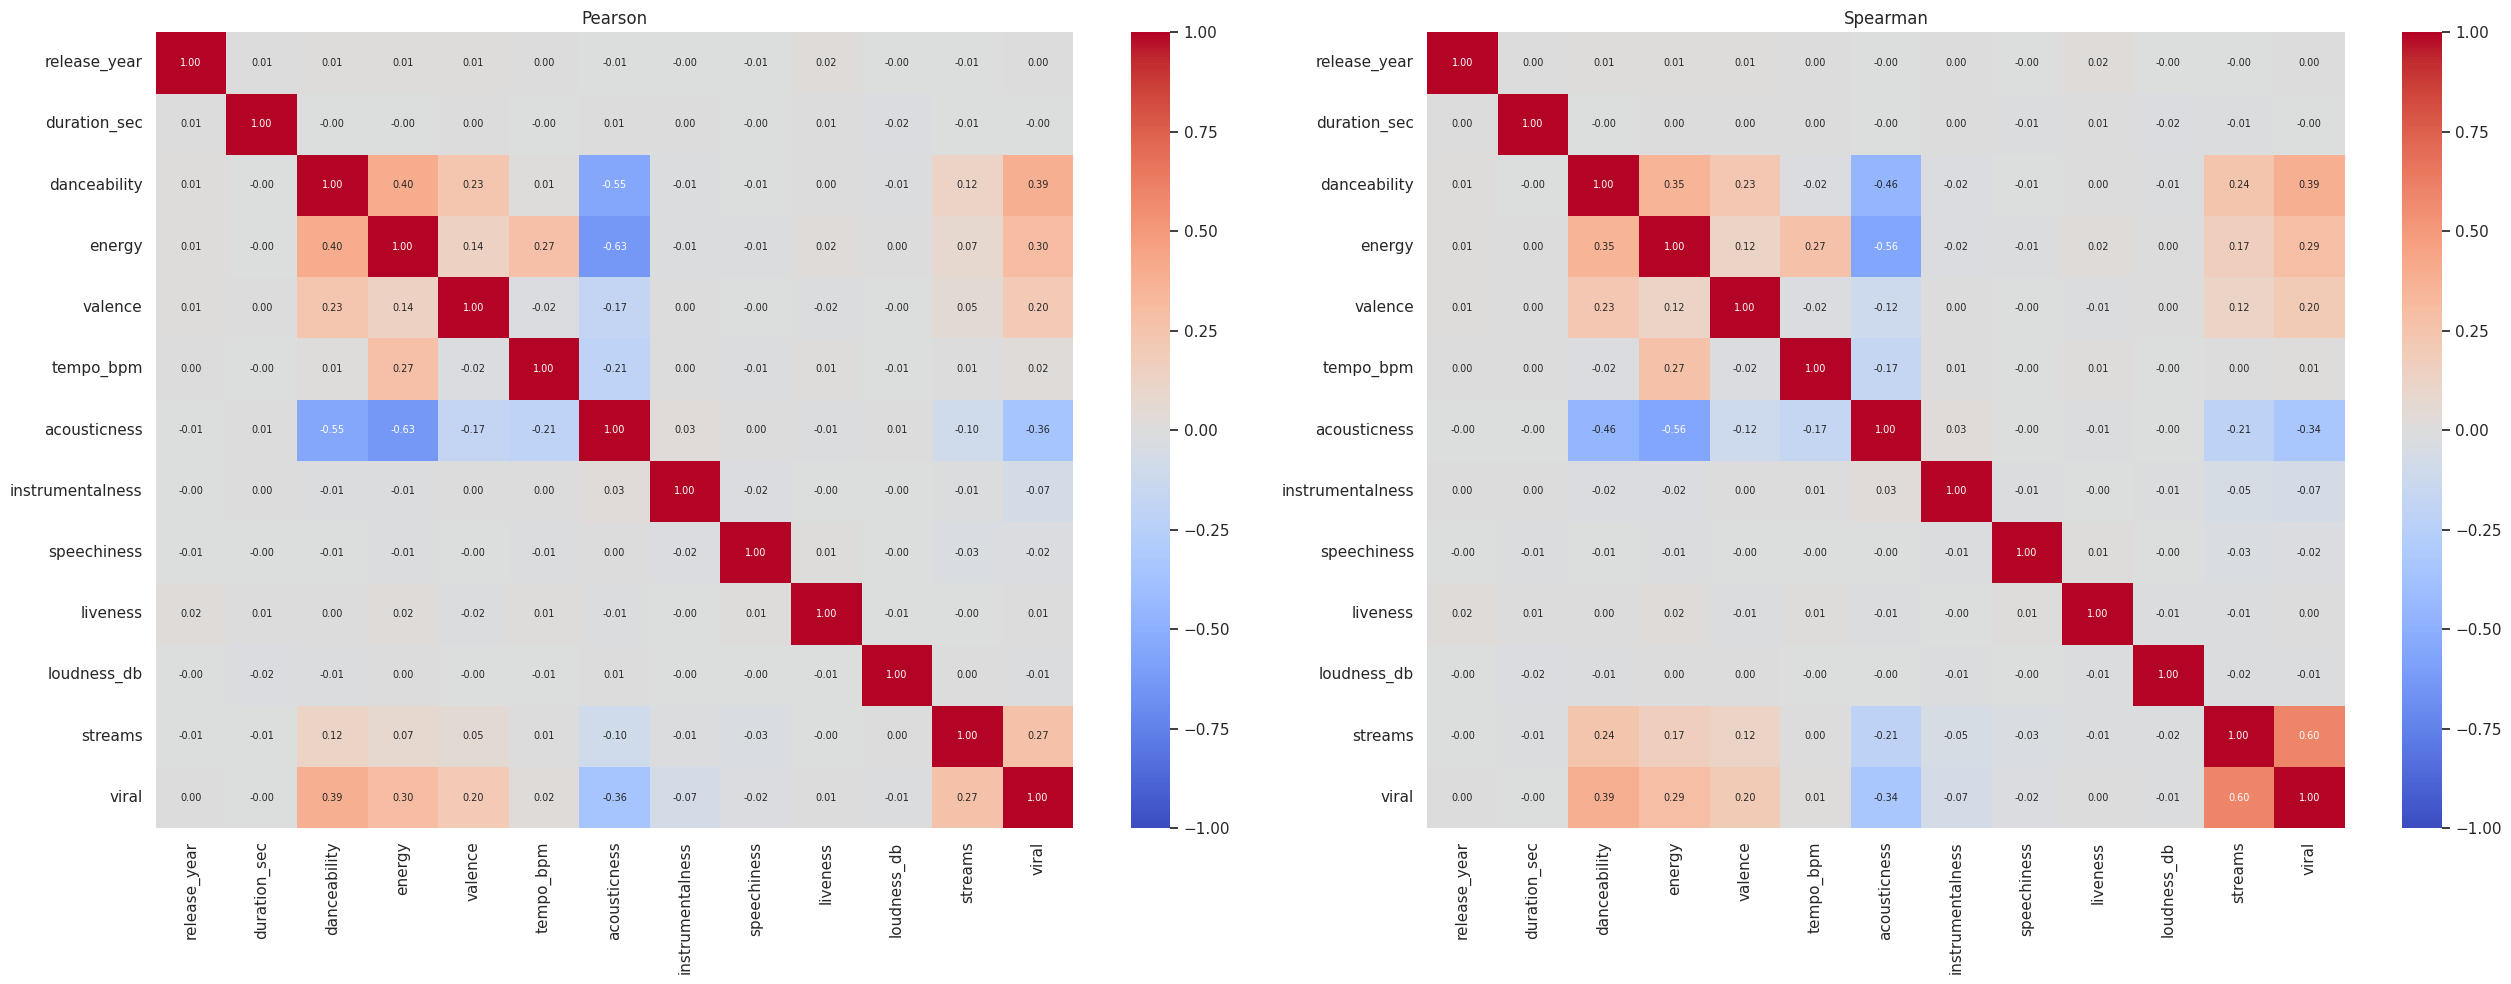

In [91]:
corr_cols = num_cols + [TARGET]
pearson = clean[corr_cols].corr(method="pearson")
spearman = clean[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(26, 10))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

In [92]:
tcorr = pd.DataFrame({"pearson": pearson[TARGET], "spearman": spearman[TARGET]}).drop(TARGET)
display(tcorr.sort_values("spearman", ascending=False).round(3))
print("danceability-energy Pearson:", round(clean["danceability"].corr(clean["energy"]), 4))
print("streams-viral: Pearson =", round(clean["streams"].corr(clean[TARGET]), 4),
      "| Spearman =", round(clean["streams"].corr(clean[TARGET], method="spearman"), 4))

,pearson,spearman
streams,0.266,0.595
danceability,0.386,0.390
energy,0.302,0.294
valence,0.205,0.202
tempo_bpm,0.016,0.014
liveness,0.005,0.004
release_year,0.004,0.004
duration_sec,-0.005,-0.005
loudness_db,-0.012,-0.012
speechiness,-0.018,-0.017


danceability-energy Pearson: 0.4047
streams-viral: Pearson = 0.2664 | Spearman = 0.5953


## Encoding

In [93]:
model_df = clean.copy()
model_df = model_df.drop(columns=["artist", "viral_label", "era", "streams_group"])
if DROP_STREAMS:
    model_df = model_df.drop(columns="streams")


assert set(model_df[TARGET].unique()) == {0, 1}

#sıralanmamışsütun
nominal = ["genre"]
print("Baseline (silinən) kateqoriya:", {c: sorted(model_df[c].unique())[0] for c in nominal})
model_df = pd.get_dummies(model_df, columns=nominal, drop_first=True, dtype=int)

assert model_df.isna().sum().sum() == 0, "Encoding zamanı NaN yarandı"
print("Shape after encoding:", model_df.shape)
print("Non-numeric columns left:", model_df.select_dtypes(exclude="number").columns.tolist())
display(model_df.head())

Baseline (silinən) kateqoriya: {'genre': 'Classical'}
Shape after encoding: (10000, 22)
Non-numeric columns left: []


,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral,genre_Country,genre_Electronic,genre_Hip-Hop,genre_Indie,genre_Jazz,genre_Latin,genre_Pop,genre_R&B,genre_Rock
0,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1,0,0,0,0,0,0,1,0,0
1,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1,0,1,0,0,0,0,0,0,0
2,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1,0,0,1,0,0,0,0,0,0
3,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0,0,0,0,0,0,0,0,0,0
4,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1,0,0,0,0,0,0,1,0,0


##  Multikolinearlıq

In [95]:
X = model_df.drop(columns=TARGET)
y = model_df[TARGET]

def vif_table(X):

    Xf = (X.astype(float) - X.astype(float).mean()) / X.astype(float).std()
    rows = []
    for c in Xf.columns:
        others = Xf.drop(columns=c)
        r2 = LinearRegression().fit(others, Xf[c]).score(others, Xf[c])
        rows.append((c, np.inf if r2 >= 1 else 1 / (1 - r2)))
    return pd.DataFrame(rows, columns=["feature", "VIF"]).sort_values("VIF", ascending=False).reset_index(drop=True)

vif = vif_table(X)
display(vif.round(3))


vif_np = np.diag(np.linalg.inv(X.corr().values))
assert np.allclose(np.sort(vif_np), np.sort(vif["VIF"].values), rtol=1e-6)
print("Çarpaz yoxlama uğurludur. Maksimum VIF:", round(vif["VIF"].max(), 3))

,feature,VIF
0,genre_Electronic,7.757
1,genre_Rock,7.440
2,genre_Latin,7.426
3,genre_Hip-Hop,6.990
4,genre_Pop,6.582
5,genre_R&B,5.116
6,genre_Country,4.328
7,acousticness,4.024
8,genre_Indie,3.981
9,genre_Jazz,2.647


Çarpaz yoxlama uğurludur. Maksimum VIF: 7.757


In [96]:
corr_abs = X.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
print("Ən çox korrelyasiyalı əlamət cütləri (|r|):")
display(upper.stack().sort_values(ascending=False).head(8).round(3))

Ən çox korrelyasiyalı əlamət cütləri (|r|):


energy        acousticness    0.633
danceability  acousticness    0.548
              energy          0.405
valence       genre_Latin     0.359
energy        genre_Jazz      0.359
              genre_Rock      0.352
danceability  genre_Latin     0.333
acousticness  genre_Jazz      0.319
dtype: float64

## Train

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of viral in train:", round(y_train.mean(), 4), "| in test:", round(y_test.mean(), 4))
assert len(set(X_train.index) & set(X_test.index)) == 0

Train: (8000, 21) | Test: (2000, 21)
Share of viral in train: 0.3605 | in test: 0.3605


## Scaling


In [98]:
scale_cols = [c for c in num_cols if c in X.columns]
scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "robust": RobustScaler()}[SCALER]

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])

print("Scaler:", SCALER, "| scaled columns:", scale_cols)
print("\nTrain after scaling:")
display(X_train_s[scale_cols].agg(["mean", "std", "min", "max"]).round(3))
print("Test after scaling (0 və 1-ə yaxın, amma tam bərabər deyil, bu normaldır):")
display(X_test_s[scale_cols].agg(["mean", "std"]).round(3))

Scaler: standard | scaled columns: ['release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db', 'streams']

Train after scaling:


,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams
mean,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.623,-2.993,-3.191,-3.465,-3.264,-3.199,-1.121,-1.102,-1.256,-1.620,-3.615,-0.239
max,1.631,4.512,2.016,1.857,2.342,3.223,2.694,4.476,4.024,3.841,2.661,43.466


Test after scaling (0 və 1-ə yaxın, amma tam bərabər deyil, bu normaldır):


,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams
mean,0.017,0.002,-0.028,-0.022,0.001,0.029,0.033,-0.008,0.009,0.004,-0.050,-0.002
std,0.998,1.026,1.014,1.019,0.989,0.997,1.028,1.001,1.012,1.011,0.983,0.773


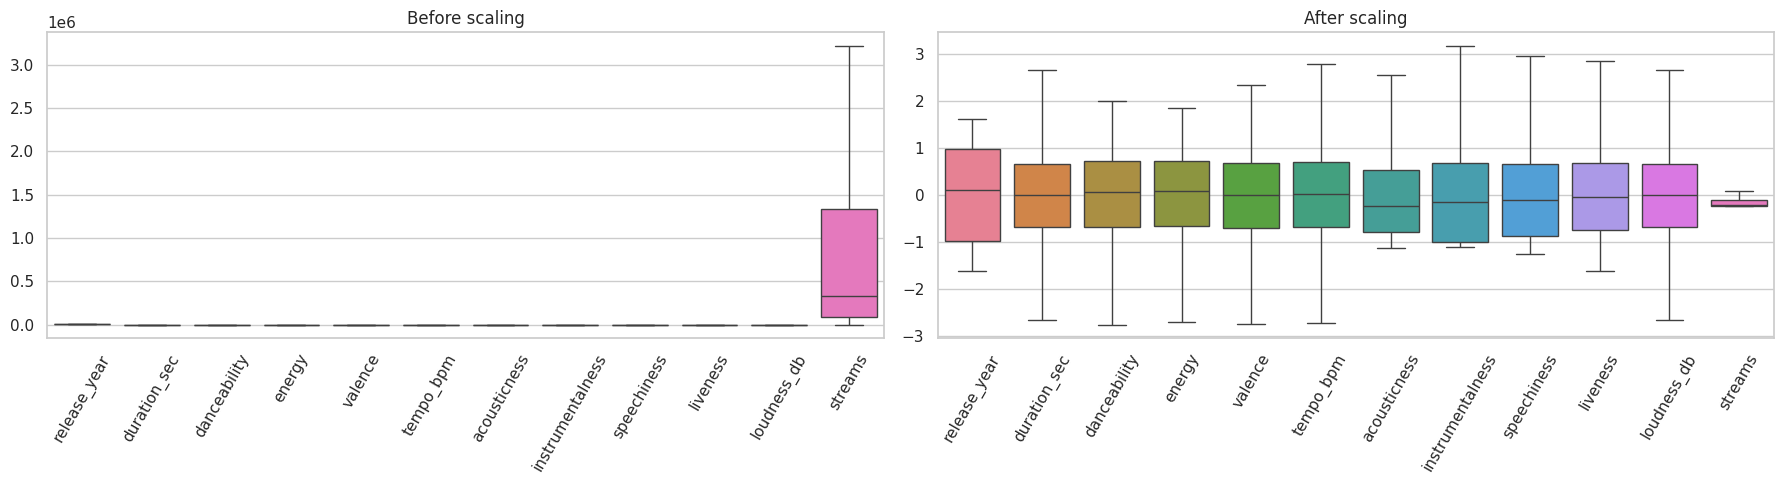

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.boxplot(data=X_train[scale_cols], showfliers=False, ax=axes[0]); axes[0].set_title("Before scaling")
sns.boxplot(data=X_train_s[scale_cols], showfliers=False, ax=axes[1]); axes[1].set_title("After scaling")
for ax in axes: ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

In [100]:
#streams üçün üç scalerin müqayisəsi
if "streams" in X_train.columns:
    cmp = {}
    for name, sc in [("standard", StandardScaler()), ("minmax", MinMaxScaler()), ("robust", RobustScaler())]:
        cmp[name] = pd.Series(sc.fit_transform(X_train[["streams"]]).ravel()).describe()
    display(pd.DataFrame(cmp).round(3))

,standard,minmax,robust
count,8000.000,8000.000,8000.000
mean,-0.000,0.005,1.674
std,1.000,0.023,8.106
min,-0.239,0.000,-0.261
25%,-0.230,0.000,-0.192
50%,-0.206,0.001,0.000
75%,-0.107,0.003,0.808
max,43.466,1.000,354.001


In [101]:
for name, part in [("X_train_s", X_train_s), ("X_test_s", X_test_s)]:
    print(name, part.shape, "| NaN:", int(part.isna().sum().sum()),
          "| non-numeric columns:", part.select_dtypes(exclude="number").shape[1])
print("Train and test have identical columns:", list(X_train_s.columns) == list(X_test_s.columns))
print("Total features:", X_train_s.shape[1])

clean.to_csv("viral_cleaned.csv", index=False)
X_train_s.assign(**{TARGET: y_train}).to_csv("viral_train_ready.csv", index=False)
X_test_s.assign(**{TARGET: y_test}).to_csv("viral_test_ready.csv", index=False)
print("Saved: viral_cleaned.csv, viral_train_ready.csv, viral_test_ready.csv")

X_train_s (8000, 21) | NaN: 0 | non-numeric columns: 0
X_test_s (2000, 21) | NaN: 0 | non-numeric columns: 0
Train and test have identical columns: True
Total features: 21
Saved: viral_cleaned.csv, viral_train_ready.csv, viral_test_ready.csv
